In [1]:
from auxillaryFunctions import *
np.random.seed(0)



STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.22 #-2.25
GPeBias = -0.23

TS = 0.04
nSTN = 1
nCTX = 1
CTXrate = 0.001*3.1
nCTX_STN = 1

nSegments = 3

coupling = 0.25
STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]


STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]

neuronDict = {"STN":STNNeurons}
spikerDict = {"CTX":CTXSpikers}

CTX_STNEL = [[0,0,0],[0,0,1],[0,0,3]]
CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.02,0.2,TS,edgeList=CTX_STNEL)

synapseDict = {"CTXToSTN":CTXToSTNSynapses}

simData,connectionToChannelMap = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 37


In [2]:
[(x["pre"],x["post"],x["synapse"]["name"]) for x in CTXToSTNSynapses]
#post synaptic channels are not being applied to the correct segment.
connectionToChannelMap["CTXToSTN"]

{0: 28, 1: 29, 2: 30, 3: 31, 4: 32, 5: 33, 6: 34, 7: 35, 8: 36}

  0%|          | 0/25000 [00:00<?, ?it/s]

 10%|█         | 2523/25000 [00:00<00:02, 8128.41it/s]c:\Users\CathalMcLoughlin\Documents\GitHub\pythonCPPtesting.ipynb\auxillaryFunctions.py:50: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))
100%|██████████| 25000/25000 [00:03<00:00, 8318.13it/s]


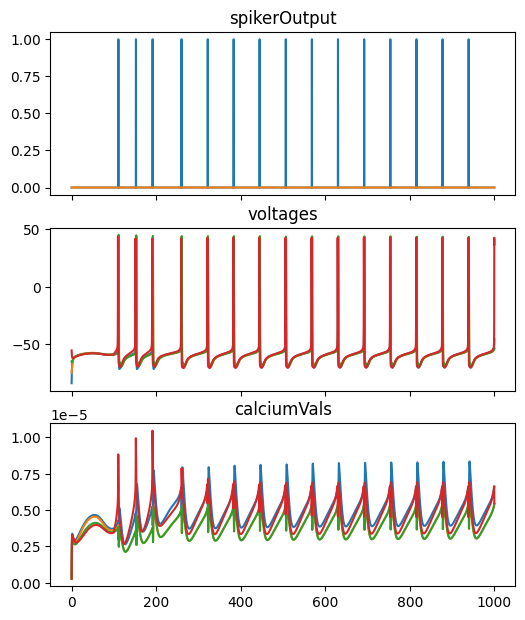

In [3]:
stimInfoSpikes = {}
#syns = [i for i,n in enumerate(simData["name"]) if n == "AMPAR"] #"AMPAR" #GABA
#syns = [val for key,val in connectionToChannelMap["CTXToSTN"].items()]
syns = [34,35,36]
stimSynapse(stimInfoSpikes,syns,100,200+2*TS,TS)
# stimSynapse(stimInfoSpikes,syns,200,250+2*TS,TS)
stimInfoCurrents = {}
# stimBiasCurrent(stimInfoCurrents,[0],-20, 200,200+20*TS,TS)

runTime = 1000

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])

data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,nSamples=None, useTQDM=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","spikerOutput"])

#TODO: add spike recording to cpp side
keysToPlot = ["spikerOutput","voltages","calciumVals","time"]
standardPlot({key:data[key] for key in keysToPlot})

C:\Users\CathalMcLoughlin\AppData\Local\Temp\ipykernel_13820\1729161385.py:1: MatplotlibDeprecationWarning: Passing label as a length 4 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(data["voltages"][:,3],label=[i for i in range(4)])


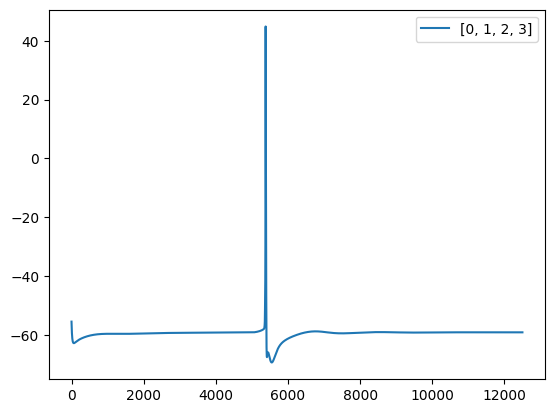

In [42]:
plt.plot(data["voltages"][:,3],label=[i for i in range(4)])
plt.legend()

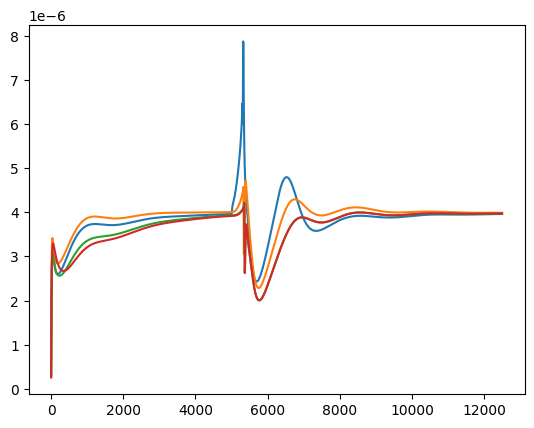

In [38]:
plt.plot(data["calciumVals"][:,1])
plt.plot(data["calciumVals"][:,0])
plt.plot(data["calciumVals"][:,2])
plt.plot(data["calciumVals"][:,3])

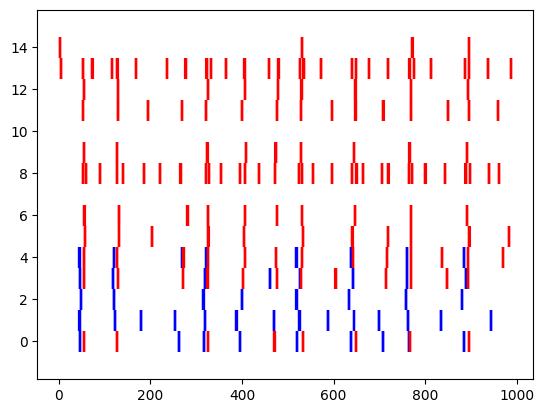

In [ ]:
def getPopSpikeTrains(simDataPy,data):
    neuronToSpiker = {}
    for i,val in enumerate(simDataPy["spikerPreNeuron"]):
        if val not in neuronToSpiker.keys():
            neuronToSpiker[i] = int(val)

    neuronPopToSpiker = {}
    spikerToPop = {}

    for i,name in enumerate(simDataPy["neuronName"]):
        if name not in neuronPopToSpiker:
            neuronPopToSpiker[name] = []
        neuronPopToSpiker[name].append(i)
        spikerToPop[i] = name

    #spikes = data["spikerOutput"][:,neuronPopToSpiker["GPe"][1]]
    nNeurons = simDataPy["nNeurons"]
    spikeTimes = [[] for i in range(nNeurons)]
    for timeInd,neurInd in zip(*np.where(data["spikerOutput"][:,0:nNeurons]==1)):
        spikeTimes[neurInd].append(float(data["time"][timeInd]))

    popSpikeTrains = {k:[] for k in neuronPopToSpiker.keys()}
    for i,trains in enumerate(spikeTimes):
        popSpikeTrains[spikerToPop[i]].append(trains)
    return popSpikeTrains

popSpikeTrains = getPopSpikeTrains(simDataPy,data)
fig,ax = plt.subplots(1,1)
ax.eventplot(popSpikeTrains["STN"],color="b");
ax.eventplot(popSpikeTrains["GPe"],color="r");

In [ ]:
spikeCounts = {}
for i,train in enumerate(popSpikeTrains["GPe"]):
    anySpike = len(train)>0
    ISI = np.diff(train)
    ISIoverThresh = sum(ISI>1.0)
    nSpikes = anySpike+ISIoverThresh
    spikeCounts[i] = int(nSpikes)*1000/runTime

spikeCounts

{0: 8.0,
 1: 0.0,
 2: 0.0,
 3: 12.0,
 4: 13.0,
 5: 11.0,
 6: 10.0,
 7: 0.0,
 8: 32.0,
 9: 9.0,
 10: 0.0,
 11: 15.0,
 12: 9.0,
 13: 28.0,
 14: 4.0}

In [ ]:
simDataPy["spikeTrains"]; #NOTE: I dont like this philosophy of this and it sholud be removed later. Keep state and recording data separate 


In [ ]:
build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

    
def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)
    print("here")
    cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)

    #trackPerfOverTime(ac)

    recordingData["time"] = tv
    return recordingData


simDataPy = deepcopy(simData)
stimInfoSpikes,stimInfoCurrents = {},{}
allChannelDataCpp = deepcopy(simData)
allChannelDataCpp["debugRecording"] = np.zeros_like(simDataPy["current"])
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=4,stimInfoSpikes=stimInfoSpikes,
                         recordingKeys = ["voltages","calciumVals","current"])

